In [1]:
import sys
sys.path.append('../UniPert/perturbation_tasks/genetic_benchmark/GEARS-adapted')

from gears import PertData, GEARS

## load UniPert model

In [2]:
import sys
sys.path.append('../UniPert')
from unipert import UniPert

unipert_encoder = UniPert(
    data_dir='../UniPert/data', 
    model_hparams = {'save_dir': "../UniPert/current_model"}
    )

💡 Model have already trained at ../UniPert/current_model. 
💡 UniPert model hyperparameters settings:
    version: v1
    out_dim: 256
    gnn_type: GCN
    layer_num: 2
    graph_type: weighted_directed
    target_embedder: ESM2
    compound_embedder: ECFP4
    device: cuda:0
    exp_name: unipert_gnn_gs_0717/GCN_2_256
    seed: 2024
    bs: 512
    epochs1: 1000
    epochs2: 1000
    lr1: 0.005
    lr2: 0.005
    wd: 1e-05
    mm: 0.99
    drop_edge_p_1: 0.1
    drop_feat_p_1: 0.3
    drop_edge_p_2: 0.3
    drop_feat_p_2: 0.1
    exp_time: 20240717-113151
    save_dir: /fionafyang/lynnymli/UniPert/saved_models/unipert_gnn_gs_0717/GCN_2_256
Loading model from ../UniPert/current_model...
💡 Constructing UniPert model...
✅ ESM2 model loaded.
✅ Reference ESM2 embedding file loaded.
✅ ESM2 embedder created.
✅ ECFP4 embedder loaded.
✅ UniPert model constructed.
✅ Pretrained model file loaded.
💡 Building a weighted_directed graph...
✅ Reference target graph prepared.


In [3]:
pert_data = PertData(data_path='../UniPert/perturbation_tasks/genetic_benchmark/data',
                     pert_encoder_type="UniPert",
                     pert_encoder=unipert_encoder
                     )
pert_data.load(data_name = 'norman')
pert_data.prepare_split(split = 'simulation', seed = 1310)
pert_data.get_dataloader(batch_size = 32, test_batch_size = 128)

Found local copy...
Found local copy...
Found local copy...


✅ Referece representations loaded.
✅ Referece representations loaded.
✅ 33913 ref compounds and 19187 ref targets encoded.
💡 Encoding 9853 genetic perturbagens with UniPert...


100%|██████████| 9853/9853 [00:35<00:00, 275.24it/s]


✅ Custom perturbagen representations saved at ../UniPert/current_model/unipert_reps.pkl.


Loaded perturbation representation with UniPert model!
These perturbations are not in the GO graph and their perturbation can thus not be predicted
['RHOXF2BB+ctrl' 'LYL1+IER5L' 'ctrl+IER5L' 'KIAA1804+ctrl' 'IER5L+ctrl'
 'RHOXF2BB+ZBTB25' 'RHOXF2BB+SET']
Local copy of pyg dataset is detected. Loading...
Done!
Local copy of split is detected. Loading...
Simulation split test composition:
combo_seen0:13
combo_seen1:50
combo_seen2:17
unseen_single:41
Done!
Creating dataloaders....
Done!


here1


In [4]:
unipert = GEARS(pert_data, 
                device = 'cuda:0', 
                exp_name='UniPert')
unipert.load_pretrained('../UniPert/perturbation_tasks/genetic_benchmark/saved_models/norman/UniPert_1310')

Current running UniPert model.


## load GEARS model

In [5]:
pert_data = PertData(data_path='../UniPert/perturbation_tasks/genetic_benchmark/data',
                     pert_encoder_type="GEARS")
pert_data.load(data_name = 'norman')
pert_data.prepare_split(split = 'simulation', seed = 1310)
pert_data.get_dataloader(batch_size = 32, test_batch_size = 128)
gears = GEARS(pert_data, device = 'cuda:0', exp_name='GEARS')
gears.load_pretrained('../UniPert/perturbation_tasks/genetic_benchmark/saved_models/norman/GEARS_1310')

Found local copy...
Found local copy...
Found local copy...
These perturbations are not in the GO graph and their perturbation can thus not be predicted
['RHOXF2BB+ctrl' 'LYL1+IER5L' 'ctrl+IER5L' 'KIAA1804+ctrl' 'IER5L+ctrl'
 'RHOXF2BB+ZBTB25' 'RHOXF2BB+SET']
Local copy of pyg dataset is detected. Loading...
Done!
Local copy of split is detected. Loading...
Simulation split test composition:
combo_seen0:13
combo_seen1:50
combo_seen2:17
unseen_single:41
Done!
Creating dataloaders....
Done!


here1


Current running GEARS model.


In [14]:
test_pert_genes = set()
for i in pert_data.dataloader['test_loader'].dataset:
    test_pert_genes.add(i.pert)
test_pert_genes = list(test_pert_genes)
len(test_pert_genes)

121

## plot 

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
from matplotlib.font_manager import FontProperties, fontManager
from matplotlib.ticker import FuncFormatter

sns.set_theme(style="ticks", rc={"axes.facecolor": (0, 0, 0, 0)}, font_scale=1)
mpl.rcParams.update({
    'font.family': 'Arial',
    'axes.linewidth': 0.8,
    'axes.edgecolor': 'black',
    'axes.labelsize': 18,
    'axes.titlesize': 18,
    'xtick.labelsize': 16,
    'ytick.labelsize': 16,
    'xtick.major.width': 0.8,
    'ytick.major.width': 0.8,
    'xtick.minor.width': 0.8,
    'ytick.minor.width': 0.8,
    'legend.fontsize': 18,
    'lines.linewidth': 1.2,
    'legend.frameon': False
})

font_path = '../Helvetica.ttf' 
fontManager.addfont(font_path)
prop = FontProperties(fname=font_path)
font_name = prop.get_name()
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = [font_name] 
print("Current font settings:", plt.rcParams['font.sans-serif']) 

Current font settings: ['Helvetica']


### supp

In [11]:
def plot_perturbation_compare(query, adata, gene2idx, pred1, pred2, save_file = None,
                              set_xtick=True, set_ytick=True, ylim=(-2, 2), 
                              title="", xlabel="", ylabel="", legend=None):
    """
    Plot the perturbation of two given prediction resuts
    """


    cond2name = dict(adata.obs[['condition', 'condition_name']].values)
    gene_raw2id = dict(zip(adata.var.index.values, adata.var.gene_name.values))

    
    de_idx = [gene2idx[gene_raw2id[i]] for i in adata.uns['top_non_dropout_de_20'][cond2name[query]]]
    genes = [gene_raw2id[i] for i in
                adata.uns['top_non_dropout_de_20'][cond2name[query]]]
    truth = adata[adata.obs.condition == query].X.toarray()[:, de_idx]
    
    pred1 = pred1[de_idx]
    pred2 = pred2[de_idx]
    ctrl_means = adata[adata.obs['condition'] == 'ctrl'].to_df().mean()[
        de_idx].values

    pred1 = pred1 - ctrl_means
    pred2 = pred2 - ctrl_means
    truth = truth - ctrl_means
    truth_mean = truth.mean(axis=0)
    
    plt.figure(figsize=[11.5, 3])

    plt.violinplot(truth, 
                showmeans=False,    
                widths=0.7,
                )    

    scatter_size = 65
    for i in range(truth_mean.shape[0]):
        if i == 0:
            _ = plt.scatter(i+1, truth_mean[i], color='royalblue', label='Mean of truth', s=scatter_size, alpha=0.75)
        else:
            _ = plt.scatter(i+1, truth_mean[i], color='royalblue', s=scatter_size, alpha=0.75)

    for i in range(pred1.shape[0]):
        if i == 0:
            _ = plt.scatter(i+1, pred1[i], color='gold', label='GEARS', s=scatter_size, alpha=0.75)
        else:
            _ = plt.scatter(i+1, pred1[i], color='gold', s=scatter_size, alpha=0.75)

    for i in range(pred2.shape[0]):
        if i == 0:
            _ = plt.scatter(i+1, pred2[i], color='red', label='UniPert', s=scatter_size, alpha=0.75)
        else:
            _ = plt.scatter(i+1, pred2[i], color='red', s=scatter_size, alpha=0.75)


    plt.axhline(0, linestyle="dashed", color = 'grey', label='Control', linewidth=2)

    ax = plt.gca()
    if set_xtick:
        ax.spines['bottom'].set_position(('outward', 0))
        ax.spines['bottom'].set_bounds(1, len(genes))
        ax.set_xlim(0, len(genes) + 1)
        ax.set_xticks(np.arange(1, len(genes) + 1))
        ax.xaxis.set_ticklabels(genes, rotation = 90)
        
    else:
        ax.set_xlim(0, len(genes) + 1)
        ax.set_xticks([])
        ax.spines['bottom'].set_bounds(0, 0)

    if set_ytick: 
        ax.set_ylim((ylim[0]-1, ylim[1]+1))
        ax.set_yticks(np.arange(ylim[0], ylim[1]+1, 2))
        # ax.xaxis.set_ticklabels(genes)
        ax.spines['left'].set_bounds((ylim[0], ylim[1]))
    else:
        ax.set_yticks([])
        ax.spines['left'].set_bounds(0, 0)

    ax.set_ylabel(ylabel, labelpad=10, fontsize=22)
    ax.set_xlabel(xlabel, labelpad=5, fontsize=22)

    plt.title(title, fontdict={'size': 18}, y=0.9)
    plt.tick_params(axis='x', which='major', pad=5, length=3)
    plt.tick_params(axis='y', which='major', pad=5, length=3)
    if legend:
        plt.legend(loc='upper center', 
        bbox_to_anchor=(0.5, 1.3), 
        facecolor='white', frameon=True, 
        fontsize=18, 
        ncol=4,
        handlelength=1,
        handletextpad=0.2)
    
    sns.despine()
    if save_file:
        plt.savefig(save_file, bbox_inches='tight', dpi=300, transparent=True)
    plt.show()

In [12]:
adata = gears.adata
gene2idx = gears.node_map

In [15]:
test_single = []
for i in test_pert_genes:
    query = i
    query_ = [q for q in query.split('+') if q != 'ctrl']

    if len(query_) == 1:
        test_single.append(query_[0])

len(test_single)

41

In [16]:
'CBL' in test_single, 'CNN1' in test_single, 'CBL+CNN1' in test_pert_genes

(False, False, False)

Current font settings: ['Helvetica']


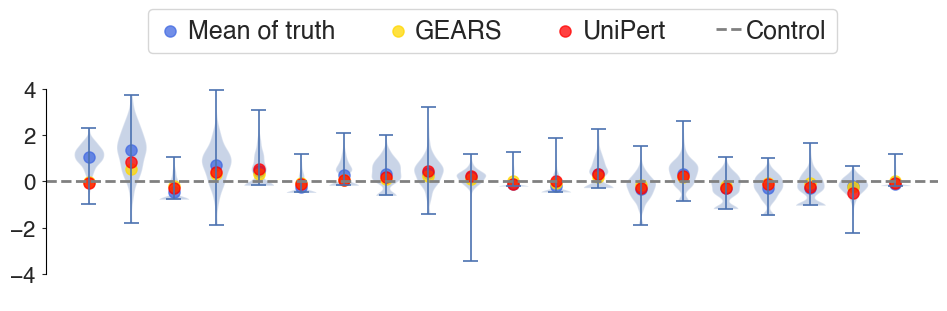

In [ ]:
for i in ['CBL+ctrl']:
    query = i
    query_ = [q for q in query.split('+') if q != 'ctrl']

    pred1 = gears.predict([query_])['_'.join(query_)]
    pred2 = unipert.predict([query_])['_'.join(query_)]

    plot_perturbation_compare(query, adata, gene2idx, pred1, pred2, 
                              set_xtick=False,
                              ylim=(-4, 4),
                              legend=True
                              )

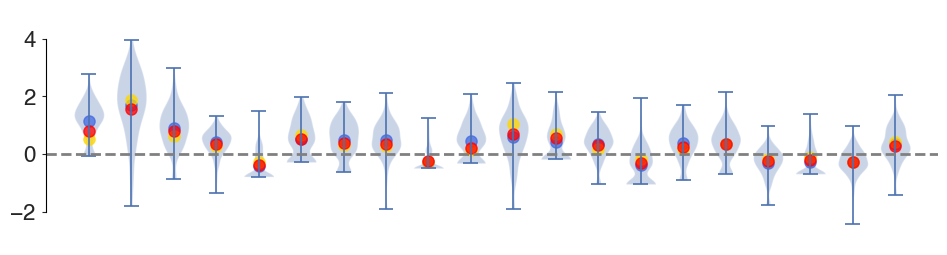

In [17]:
for i in ['CNN1+ctrl']:
    query = i
    query_ = [q for q in query.split('+') if q != 'ctrl']

    pred1 = gears.predict([query_])['_'.join(query_)]
    pred2 = unipert.predict([query_])['_'.join(query_)]

    plot_perturbation_compare(query, adata, gene2idx, pred1, pred2, 
                              set_xtick=False,
                              ylim=(-2, 4),
                              )

Current font settings: ['Helvetica']


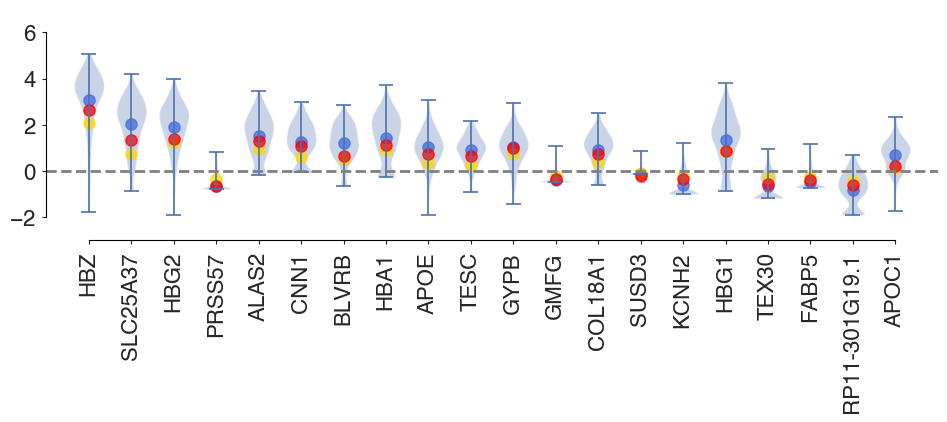

In [ ]:
for i in ['CBL+CNN1']:
    query = i
    query_ = [q for q in query.split('+') if q != 'ctrl']

    pred1 = gears.predict([query_])['_'.join(query_)]
    pred2 = unipert.predict([query_])['_'.join(query_)]

    plot_perturbation_compare(query, adata, gene2idx, pred1, pred2, 
                              ylim=(-2, 6),
                              )

In [18]:
'CEBPB' in test_single, 'FOSB' in test_single, 'CEBPB+FOSB' in test_pert_genes

(True, False, False)

Current font settings: ['Helvetica']


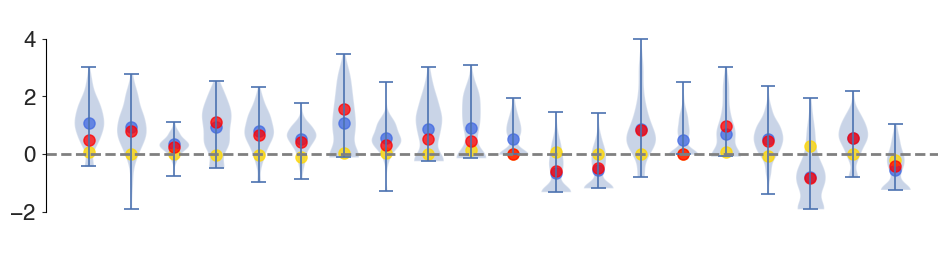

In [ ]:
for i in ['CEBPB+ctrl']:
    query = i
    query_ = [q for q in query.split('+') if q != 'ctrl']

    pred1 = gears.predict([query_])['_'.join(query_)]
    pred2 = unipert.predict([query_])['_'.join(query_)]

    plot_perturbation_compare(query, adata, gene2idx, pred1, pred2, 
                            set_xtick=False,
                            ylim=(-2, 4),
                            )

Current font settings: ['Helvetica']


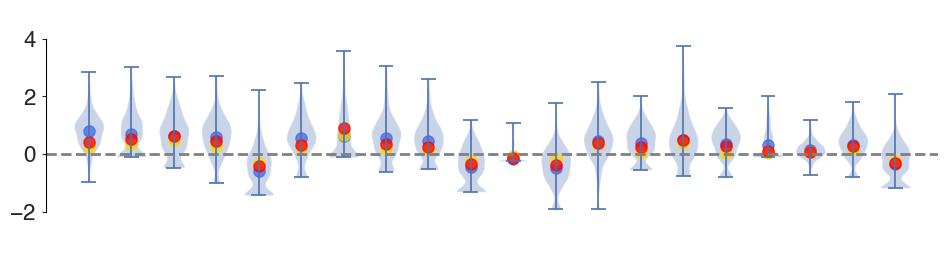

In [ ]:
for i in ['FOSB+ctrl']:
    query = i
    query_ = [q for q in query.split('+') if q != 'ctrl']

    pred1 = gears.predict([query_])['_'.join(query_)]
    pred2 = unipert.predict([query_])['_'.join(query_)]

    plot_perturbation_compare(query, adata, gene2idx, pred1, pred2, 
                            set_xtick=False,
                            ylim=(-2, 4),
                            )

Current font settings: ['Helvetica']


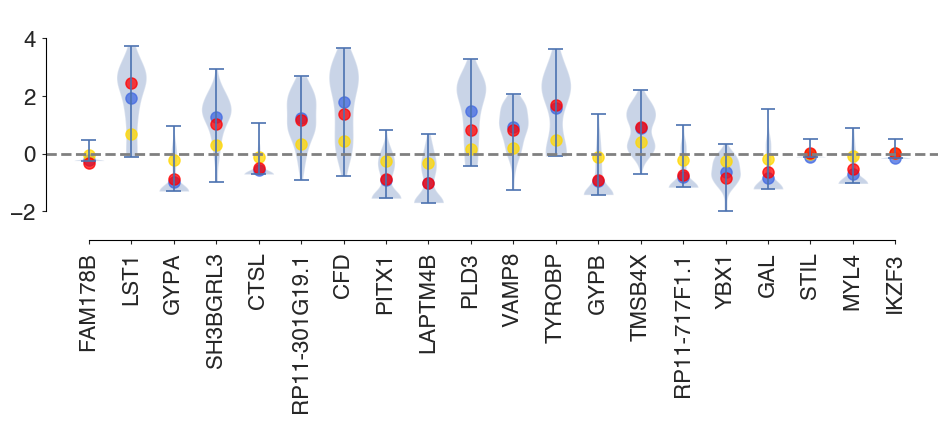

In [ ]:
for i in ['FOSB+CEBPB']:
    query = i
    query_ = [q for q in query.split('+') if q != 'ctrl']

    pred1 = gears.predict([query_])['_'.join(query_)]
    pred2 = unipert.predict([query_])['_'.join(query_)]

    plot_perturbation_compare(query, adata, gene2idx, pred1, pred2, 
                              ylim=(-2, 4),
                              )